<a href="https://colab.research.google.com/github/arushikumarics24-beep/BIS_LAB/blob/main/cuckcoo_optimization_problem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

               PATH PLANNING METRICS              
Start Position:                 (2, 2)
Goal Position:                  (18, 18)
Theoretical Minimum Distance:    22.6274 (Straight line)
Optimized Path Length:          76.3748
Optimization Score (w/ Penalty): 76.3748
Safe Route Found (No Collisions): True


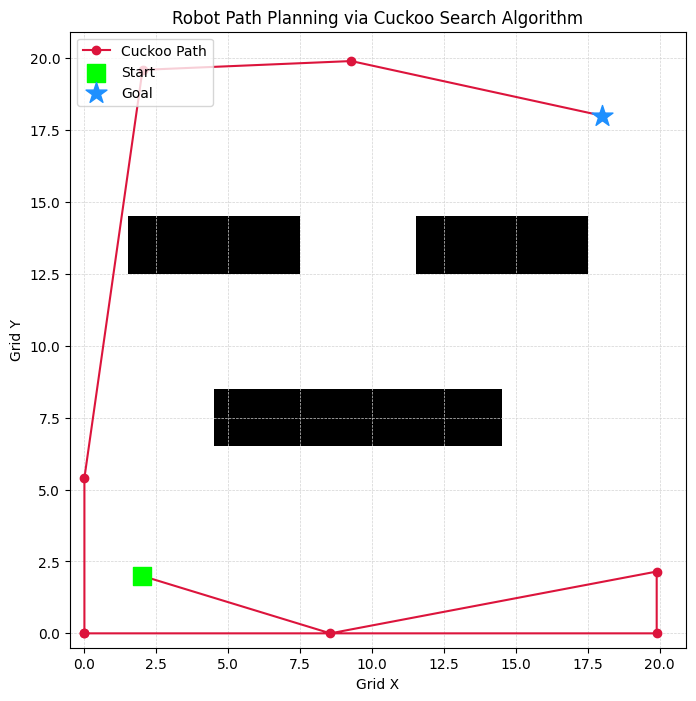

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as special

class CuckooSearchPathPlanner:
    def __init__(self, grid, start, goal, num_cuckoos=25, max_iter=200, pa=0.25):
        """
        grid: 2D numpy array (0 for free space, 1 for obstacles)
        start: tuple (x, y) starting coordinates
        goal: tuple (x, y) target coordinates
        """
        self.grid = grid
        self.grid_shape = grid.shape
        self.start = np.array(start, dtype=float)
        self.goal = np.array(goal, dtype=float)

        self.num_cuckoos = num_cuckoos
        self.max_iter = max_iter
        self.pa = pa  # Discovery rate of alien eggs

        # We define a path by N intermediate waypoints between start and goal
        self.num_waypoints = 8
        # Total dimensions to optimize = num_waypoints * 2 (x and y for each waypoint)
        self.dim = self.num_waypoints * 2

        # Calculate straight-line distance for baseline metrics
        self.min_possible_dist = np.linalg.norm(self.goal - self.start)

    def _is_obstacle(self, x, y):
        """Checks if a continuous coordinate falls inside an obstacle or out of bounds."""
        ix, iy = int(np.floor(x)), int(np.floor(y))
        if ix < 0 or ix >= self.grid_shape[0] or iy < 0 or iy >= self.grid_shape[1]:
            return True # Out of bounds treated as obstacle
        return self.grid[ix, iy] == 1

    def _evaluate_path(self, decision_variables):
        """Calculates fitness. Goal: Minimize total length + heavy obstacle penalties."""
        # Reshape variables into distinct (x, y) waypoints
        waypoints = decision_variables.reshape((self.num_waypoints, 2))

        # Construct full path sequence: Start -> Waypoints -> Goal
        full_path = np.vstack([self.start, waypoints, self.goal])

        total_length = 0.0
        obstacle_penalty = 0.0

        # Step through segments of the path to calculate length and collision checks
        for i in range(len(full_path) - 1):
            p1 = full_path[i]
            p2 = full_path[i+1]

            segment_length = np.linalg.norm(p2 - p1)
            total_length += segment_length

            # High-resolution sampling along the line segment to detect obstacles
            num_samples = max(int(segment_length * 3), 5)
            for t in np.linspace(0, 1, num_samples):
                check_pt = p1 + t * (p2 - p1)
                if self._is_obstacle(check_pt[0], check_pt[1]):
                    obstacle_penalty += 500.0 # Heavy penalty per collision point

        # Fitness function: lower is better
        return total_length + obstacle_penalty

    def _levy_flight(self, beta=1.5):
        """Generates a step from the Lévy distribution using Mantegna's algorithm."""
        sigma = (special.gamma(1 + beta) * np.sin(np.pi * beta / 2) /
                 (special.gamma((1 + beta) / 2) * beta * 2**((beta - 1) / 2)))**(1 / beta)
        u = np.random.normal(0, sigma, size=self.dim)
        v = np.random.normal(0, 1, size=self.dim)
        step = u / (np.abs(v)**(1 / beta))
        return step

    def plan_path(self):
        # Initialize cuckoo nests randomly within bounds of the grid map
        max_x, max_y = self.grid_shape[0], self.grid_shape[1]
        nests = np.random.rand(self.num_cuckoos, self.dim)
        nests[:, 0::2] *= max_x # Scale X components
        nests[:, 1::2] *= max_y # Scale Y components

        # Evaluate initial population
        fitness = np.array([self._evaluate_path(nest) for nest in nests])

        # Track the global best path found
        best_idx = np.argmin(fitness)
        best_nest = nests[best_idx].copy()
        best_fitness = fitness[best_idx]

        # Main optimization loop
        for iteration in range(self.max_iter):
            # 1. Generate a new cuckoo via Levy Flight from a random nest
            i = np.random.randint(0, self.num_cuckoos)
            step = self._levy_flight()

            # Step size scales relative to distance from global best
            new_nest = nests[i] + 0.01 * step * (nests[i] - best_nest)

            # Keep within grid boundaries
            new_nest[0::2] = np.clip(new_nest[0::2], 0, max_x - 0.1)
            new_nest[1::2] = np.clip(new_nest[1::2], 0, max_y - 0.1)

            # Evaluate new solution against a randomly chosen nest 'j'
            new_fit = self._evaluate_path(new_nest)
            j = np.random.randint(0, self.num_cuckoos)
            if new_fit < fitness[j]:
                nests[j] = new_nest
                fitness[j] = new_fit

            # 2. Abandon a fraction (pa) of worst nests and build new ones
            for k in range(self.num_cuckoos):
                if np.random.rand() < self.pa:
                    # Random walk scaled by distance between two random nests
                    rand_i1 = np.random.randint(0, self.num_cuckoos)
                    rand_i2 = np.random.randint(0, self.num_cuckoos)
                    step_size = np.random.rand() * (nests[rand_i1] - nests[rand_i2])
                    nests[k] += step_size

                    # Clip boundaries
                    nests[k, 0::2] = np.clip(nests[k, 0::2], 0, max_x - 0.1)
                    nests[k, 1::2] = np.clip(nests[k, 1::2], 0, max_y - 0.1)

                    fitness[k] = self._evaluate_path(nests[k])

            # Update the global best nest
            current_best_idx = np.argmin(fitness)
            if fitness[current_best_idx] < best_fitness:
                best_fitness = fitness[current_best_idx]
                best_nest = nests[current_best_idx].copy()

        # Format final output path
        final_waypoints = best_nest.reshape((self.num_waypoints, 2))
        final_path = np.vstack([self.start, final_waypoints, self.goal])

        # Verify if final path successfully avoids obstacles
        is_safe = best_fitness < (self.min_possible_dist * 5)

        return final_path, best_fitness, is_safe

# --- Execution Block ---
if __name__ == "__main__":
    # Create a 20x20 Grid Map (0 = Free space, 1 = Obstacle)
    grid_size = 20
    map_grid = np.zeros((grid_size, grid_size))

    # Place custom blockades/obstacles
    map_grid[5:15, 7:9] = 1
    map_grid[2:8, 13:15] = 1
    map_grid[12:18, 13:15] = 1

    start_pos = (2, 2)
    goal_pos = (18, 18)

    # Initialize and execute Cuckoo Search Planner
    planner = CuckooSearchPathPlanner(map_grid, start_pos, goal_pos, num_cuckoos=30, max_iter=250)
    path, score, safe = planner.plan_path()

    # Calculate path metrics
    straight_line_dist = planner.min_possible_dist

    # Calculate physical path length without penalties
    actual_path_length = 0.0
    for i in range(len(path) - 1):
        actual_path_length += np.linalg.norm(path[i+1] - path[i])

    print("="*50)
    print("               PATH PLANNING METRICS              ")
    print("="*50)
    print(f"Start Position:                 {start_pos}")
    print(f"Goal Position:                  {goal_pos}")
    print(f"Theoretical Minimum Distance:    {straight_line_dist:.4f} (Straight line)")
    print(f"Optimized Path Length:          {actual_path_length:.4f}")
    print(f"Optimization Score (w/ Penalty): {score:.4f}")
    print(f"Safe Route Found (No Collisions): {safe}")
    print("="*50)

    # Visualization Matrix Plot
    plt.figure(figsize=(8, 8))
    # Display grid map transposed to align standard grid coordinates with image indexing
    plt.imshow(map_grid.T, cmap='Greys', origin='lower', interpolation='none')

    # Plot Start, Goal and Path lines
    plt.plot(path[:, 0], path[:, 1], '-o', color='crimson', label='Cuckoo Path', markersize=6)
    plt.scatter(start_pos[0], start_pos[1], color='lime', marker='s', s=150, label='Start', zorder=5)
    plt.scatter(goal_pos[0], goal_pos[1], color='dodgerblue', marker='*', s=250, label='Goal', zorder=5)

    plt.title("Robot Path Planning via Cuckoo Search Algorithm")
    plt.xlabel("Grid X")
    plt.ylabel("Grid Y")
    plt.grid(True, which='both', color='lightgray', linestyle='--', linewidth=0.5)
    plt.legend(loc='upper left')
    plt.show()